In [1]:
# Copyright IonQ Inc., all rights reserved
from pickle import load, dump
import numpy as np
from plot_tools import PlotHelper, read_data, print_summary_stats, print_summary_stats_latex, print_lifetime_latex

# Survival Curves
## Toric + 422 + Concatenated Codes

In [2]:
# >>>> Read Data (generated in Analyze_Data.ipynb)
toric_x = read_data('processed_data/Mar2_Other_Beam32.dat',
    'Toric', [3,4], [1,2,3,4,5,6], 'X')
toric_z = read_data('processed_data/Mar2_Other_Beam32.dat',
    'Toric', [3,4], [1,2,3,4,5,6], 'Z')
Four22_x = read_data('processed_data/Mar2_Other_Beam32.dat',
    'FourTwoConcat', [2,4], [1,2,3,4,5,6], 'X')
Four22_z = read_data('processed_data/Mar2_Other_Beam32.dat',
    'FourTwoConcat', [2,4], [1,2,3,4,5,6], 'Z')

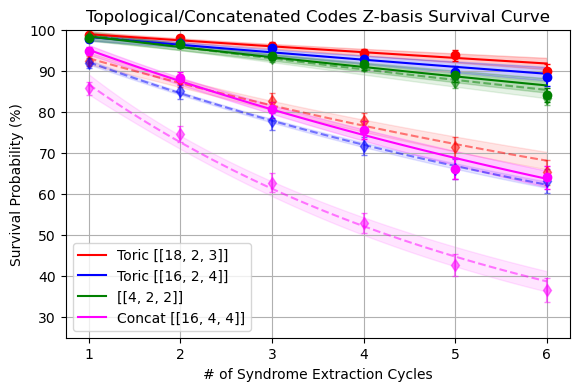

In [3]:
# >>>> Plot
basis = 'Z'
data_toric = {'Z':toric_z, 'X':toric_x}[basis]
data_422  =  {'Z':Four22_z, 'X':Four22_x}[basis]
title_lbl = f'Topological/Concatenated Codes {basis}-basis Survival Curve'

plotter = PlotHelper()
plotter.add_dataset(data_toric, '')
_, axtoric, toricstats = plotter.make_T_curves_band(title_lbl,\
    ['Toric [[18, 2, 3]]', 'Toric [[16, 2, 4]]'],
    ['red','blue'],
    shift=1, confidence=0.95, k=2, y_lim_low=0.25)

plotter = PlotHelper()
plotter.add_dataset(data_422[0:1], '')
_, ax422, _ = plotter.make_T_curves_band(title_lbl,\
    ['[[4, 2, 2]]'],
    ['green'],
    shift=1, confidence=0.95, k=2, y_lim_low=0.25, ax=axtoric)

plotter = PlotHelper()
plotter.add_dataset(data_422[1:2], '')
figall, axall, concatstats = plotter.make_T_curves_band(title_lbl,\
    ['Concat [[16, 4, 4]]'],
    ['magenta'],
    shift=1, confidence=0.95, k=4, y_lim_low=0.25, ax=ax422, show_legend=True, show_grid=True)

In [ ]:
figall.savefig("results/Other_Z.pdf")

In [6]:
# Print summary stats
print("Toric code stats: --->")
print_summary_stats(toricstats)
print("")
print("Concat code stats: --->")
print_summary_stats(concatstats)

# print_summary_stats_latex(concatstatsx, concatstatsz) # Convenience... print LaTeX table string

# (OPTIONALLY) >>>>> Also write these to file.
# with open('processed_data/Mar2_Other_fits.dat', 'wb') as f:
#     dump((toricstatsx+concatstatsx, toricstatsz+concatstatsz), f)

Toric code stats: --->
LER                     | Tau (SEC)              
7.5722e-03+/-4.0470e-03 | 6.5530e+01+/-2.3000e+01
9.7038e-03+/-5.2723e-03 | 5.1025e+01+/-1.8141e+01

Concat code stats: --->
LER                     | Tau (SEC)              
2.0719e-02+/-3.1910e-03 | 2.3629e+01+/-3.2213e+00


## BB + GB Code Plots

In [2]:
# >>>> Read Data (generated in Analyze_Data.ipynb)
BB_x = read_data('processed_data/Mar2_QLDPC_Beam32.dat',\
    'BB5final', [3,4,5], [1,2,3,4,5,6], 'X')
BB_z = read_data('processed_data/Mar2_QLDPC_Beam32.dat',\
    'BB5final', [3,4,5], [1,2,3,4,5,6], 'Z')
GB_x = read_data('processed_data/Mar2_QLDPC_Beam32.dat',\
    'GB4final', [4,5], [1,2,3,4,5,6], 'X')
GB_z = read_data('processed_data/Mar2_QLDPC_Beam32.dat',\
    'GB4final', [4,5], [1,2,3,4,5,6], 'Z')

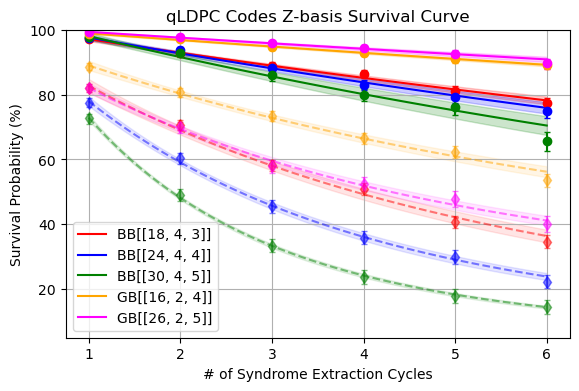

In [8]:
# >>>> Plot
basis = 'Z'
data_BB = {'Z':BB_z, 'X':BB_x}[basis]
data_GB = {'Z':GB_z, 'X':GB_x}[basis]
title_lbl = f'qLDPC Codes {basis}-basis Survival Curve'

plotter = PlotHelper()
plotter.add_dataset(data_BB, '')
_, axbb, bbstats = plotter.make_T_curves_band(title_lbl,\
    ['BB[[18, 4, 3]]','BB[[24, 4, 4]]','BB[[30, 4, 5]]'],
    ['red','blue','green','black'],
    shift=1, confidence=0.95, k=4, y_lim_low=0.05)

plotter = PlotHelper()
plotter.add_dataset(data_GB, '')
figall, axall, gbstats = plotter.make_T_curves_band(title_lbl,\
    ['GB[[16, 2, 4]]','GB[[26, 2, 5]]'],
    ['orange', 'magenta'],
    shift=1, confidence=0.95, k=2, y_lim_low=0.05, ax=axbb, show_legend=True, show_grid=True)

In [9]:
figall.savefig("/Users/tham/Desktop/trim/qldpc_Z.pdf", bbox_inches='tight')

In [10]:
# Print summary stats
print("BB code stats: --->")
print_summary_stats(bbstats)
print("")
print("GB code stats: --->")
print_summary_stats(gbstats)

# print_summary_stats_latex(gbstatsx, gbstatsz) # Convenience... print LaTeX table string

# (OPTIONALLY) >>>>> Also write these to file.
# with open('processed_data/Mar2_QLDPC_fits.dat', 'wb') as f:
#     dump((bbstatsx+gbstatsx, bbstatsz+gbstatsz), f)

BB code stats: --->
LER                     | Tau (SEC)              
1.9520e-02+/-3.9446e-03 | 2.5111e+01+/-4.3066e+00
2.1859e-02+/-3.3085e-03 | 2.2370e+01+/-3.0076e+00
3.5230e-02+/-3.0508e-02 | 1.3686e+01+/-6.5921e+00

GB code stats: --->
LER                     | Tau (SEC)              
1.4306e-02+/-2.5590e-03 | 3.4448e+01+/-5.3037e+00
1.9122e-02+/-4.2099e-03 | 2.5644e+01+/-4.7187e+00


# Lifetime Tables

In [62]:
# >>>> Import
with open('processed_data/Mar2_QLDPC_fits.dat', 'rb') as f:
    stats_qldpc = load(f)
with open('processed_data/Mar2_Other_fits.dat', 'rb') as f:
    stats_other = load(f)

In [75]:
names_qldpc = ['bb5_d3', 'bb5_d4', 'bb5_d5', 'gb4_d4', 'gb4_d5']
names_other = ['toric_d3', 'toric_d4', 'concat_422']
times_qldpc = np.array([253.057, 391.629, 514.269, 210.559, 380.469]) / 1000 / 6 # Runtimes for R=6, in s.
times_other = np.array([235.088, 210.344, 232.525]) / 1000 / 6

def update_table(table, sx, sz, n, t):
    _,_,taux,deltx = sx
    _,_,tauz,deltz = sz
    table.update({n: {
        'tx_sec': taux,
        'tz_sec': tauz,
        'sx_sec': deltx,
        'sz_sec': deltz,
        't0_sec': t,
    }})
lifetime_table = {} # Build lookup table of various code qubit lifetimes.
for sx, sz, n, t in zip(*stats_qldpc,names_qldpc,times_qldpc):
    update_table(lifetime_table, sx, sz, n, t)
for sx, sz, n, t in zip(*stats_other,names_other,times_other):
    update_table(lifetime_table, sx, sz, n, t)

def get_t_real(Tx, Tz, Sx, Sz):
    """Compute lifetime in seconds"""
    µ = 1/ ( (1/Tx + 1/(2*Tz))*1/3 )
    lo = 1/ ( (1/(Tx-Sx) + 1/(2*(Tz-Sz)))*1/3 )
    hi = 1/ ( (1/(Tx+Sx) + 1/(2*(Tz+Sz)))*1/3 )

    return µ, max(hi-µ,µ-lo)

for key in lifetime_table:
    tx_sec = lifetime_table[key]['tx_sec']
    tz_sec = lifetime_table[key]['tz_sec']
    sx_sec = lifetime_table[key]['sx_sec']
    sz_sec = lifetime_table[key]['sz_sec']
    t0_sec = lifetime_table[key]['t0_sec']
    tx = tx_sec * t0_sec
    tz = tz_sec * t0_sec
    sx = sx_sec * t0_sec
    sz = sz_sec * t0_sec

    t_real, s_real = get_t_real(tx, tz, sx, sz)

    # print(key)
    # print(f"    Tx: {tx:3.2f}+/-{sx:3.2f}, Tz: {tz:3.2f}+/-{sz:3.2f}, T_real: {t_real:3.2f}+/-{s_real:3.2f}")
    print_lifetime_latex((tx, tz, sx, sz, t_real, s_real))

& $1.06\pm0.18$ & $1.90\pm0.23$ & $2.48\pm0.40$ \tabularnewline 

& $1.46\pm0.20$ & $2.51\pm0.39$ & $3.39\pm0.47$ \tabularnewline 

& $1.17\pm0.57$ & $2.48\pm0.50$ & $2.85\pm1.26$ \tabularnewline 

& $1.21\pm0.19$ & $1.65\pm0.14$ & $2.65\pm0.36$ \tabularnewline 

& $1.63\pm0.30$ & $3.47\pm0.56$ & $3.95\pm0.71$ \tabularnewline 

& $1.33\pm0.27$ & $2.57\pm0.90$ & $3.17\pm0.75$ \tabularnewline 

& $1.23\pm0.14$ & $1.79\pm0.64$ & $2.75\pm0.53$ \tabularnewline 

& $0.72\pm0.12$ & $0.92\pm0.12$ & $1.55\pm0.25$ \tabularnewline 

